# 04 · Time-Series Forecasting with SARIMA

Executes preregistered plan **section F**: decomposition → ADF stationarity test → SARIMA selection on a training window → accuracy on a 7-day test split (MAPE, RMSE) → 30-day forecast. Prophet is not used (see preregistration); SARIMA is an allowed option.

In [1]:
import sys, warnings, pathlib, subprocess, hashlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown, Image
from rq.config import *
from rq.data import load_raw, add_calendar
from rq import stats_tests as st
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
PAL = {"Event": "#d95f02", "Holiday": "#7570b3", "Regular": "#1b9e77"}
df = add_calendar(load_raw(RAW))
print(f"rows={len(df)}  window={df.date.min().date()} .. {df.date.max().date()}  seed={SEED}")
from rq import forecasting as fc
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
y = fc.as_series(df); print(y.index.freq, len(y))

rows=30  window=2026-06-01 .. 2026-06-30  seed=20260601
<Day> 30


## 1. Decomposition into Trend, Seasonality (period 7) and Residual

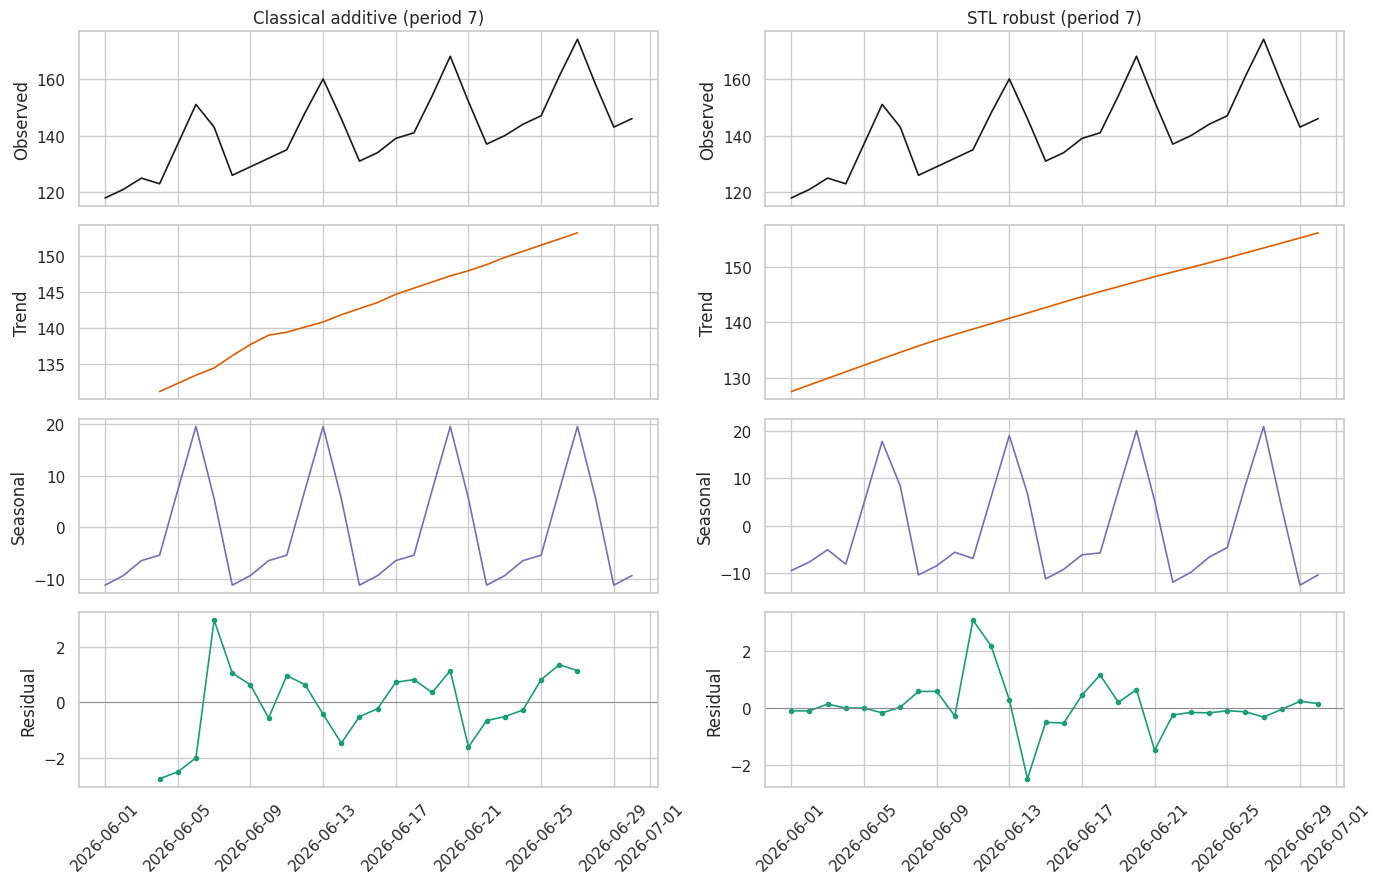

Weekly seasonal profile (classical):
 Mon   -11.20
Tue    -9.35
Wed    -6.44
Thu    -5.39
Fri     7.21
Sat    19.57
Sun     5.61
Seasonal strength (STL) = 0.99;  trend strength = 0.99


In [2]:
classical, stl = fc.decompose(y)
fig, ax = plt.subplots(4, 2, figsize=(14, 9), sharex=True)
for j, (name, dec) in enumerate([("Classical additive (period 7)", classical), ("STL robust (period 7)", stl)]):
    for i, (lab, comp) in enumerate([("Observed", dec.observed), ("Trend", dec.trend), ("Seasonal", dec.seasonal), ("Residual", dec.resid)]):
        ax[i, j].plot(comp, color=["k", "#d95f02", "#7570b3", "#1b9e77"][i], marker="o" if i == 3 else None, ms=3, lw=1.2)
        ax[i, j].set_ylabel(lab)
        if i == 3: ax[i, j].axhline(0, color="grey", lw=.6)
    ax[0, j].set_title(name)
for a in ax[-1]: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIGS / "04_decomposition.png", dpi=150); plt.show()
seas = pd.Series(classical.seasonal.iloc[:7].to_numpy(), index=[d.day_name()[:3] for d in y.index[:7]]).round(2)
print("Weekly seasonal profile (classical):\n", seas.to_string())
strength = lambda dec: max(0, 1 - np.var(dec.resid.dropna()) / np.var((dec.resid + dec.seasonal).dropna()))
print(f"Seasonal strength (STL) = {max(0, 1 - np.var(stl.resid)/np.var(stl.resid + stl.seasonal)):.2f};  trend strength = {max(0, 1 - np.var(stl.resid)/np.var(stl.resid + stl.trend)):.2f}")
pd.DataFrame({"observed": y, "trend_classical": classical.trend, "seasonal_classical": classical.seasonal, "resid_classical": classical.resid,
              "trend_stl": stl.trend, "seasonal_stl": stl.seasonal, "resid_stl": stl.resid}).round(3).to_csv(TABLES / "04_decomposition.csv")

## 2. Stationarity: Augmented Dickey-Fuller and differencing
Null hypothesis of ADF: a unit root is present (non-stationary). Preregistered rule: difference only while p ≥ 0.05 (max 2). ADF has low power at n = 30 and a constant-only specification does not model a deterministic trend/season, so ADF is complemented by ACF/PACF and by choosing the seasonal difference D with AICc.

,differences,adf_stat,p_value,used_lag,nobs,crit_5pct,stationary
0,0,-3.2872,0.0155,3,26,-2.9812,True


d from preregistered ADF rule: 0


,series,n,adf,p,stationary_at_5pct
0,level,30,-3.2872,0.0155,True
1,diff(1),29,-7.8895,0.0000,True
2,seasonal diff(7),23,-2.4666,0.1238,False


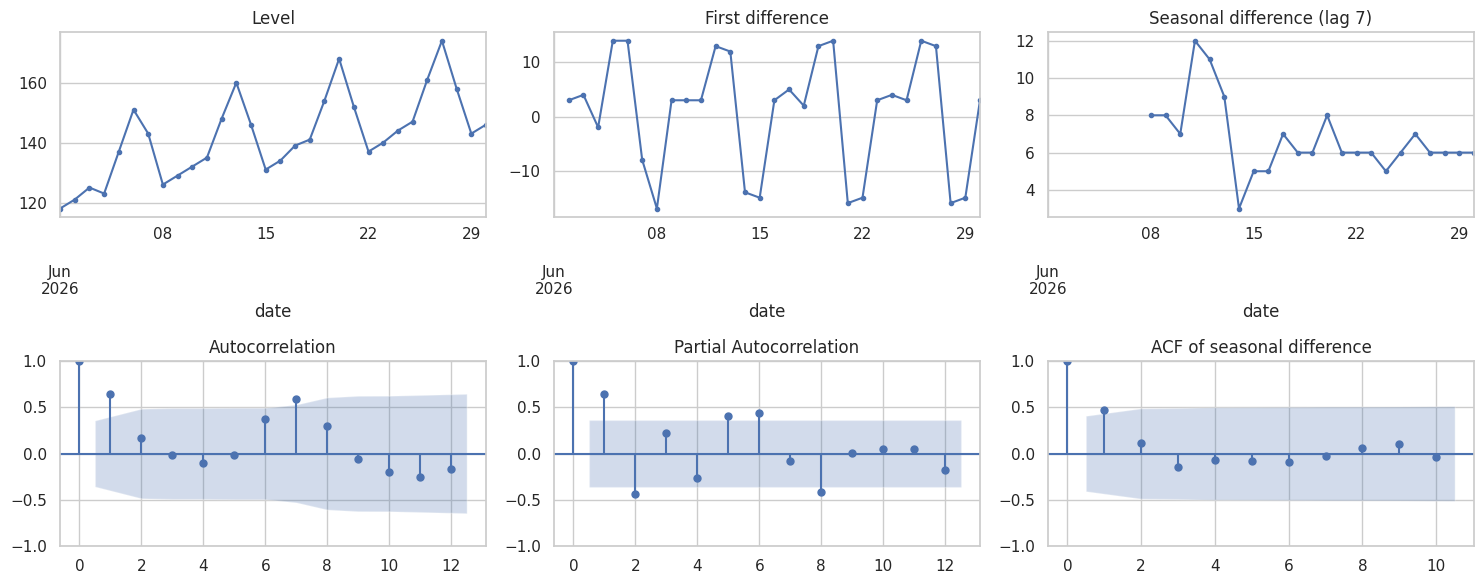

In [3]:
adf, d_rule = fc.adf_table(y); display(adf.round(4)); print("d from preregistered ADF rule:", d_rule); adf.round(4).to_csv(TABLES / "04_adf.csv", index=False)
# illustration only (not used to choose d): ADF after first and seasonal differencing
ill = []
for name, s in {"level": y, "diff(1)": y.diff().dropna(), "seasonal diff(7)": y.diff(7).dropna()}.items():
    r = fc.adfuller(s, regression="c", autolag="AIC", maxlag=3, regresults=False); ill.append(dict(series=name, n=len(s), adf=r[0], p=r[1], stationary_at_5pct=r[1] < .05))
display(pd.DataFrame(ill).round(4))
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
y.plot(ax=ax[0, 0], marker="o", ms=3); ax[0, 0].set_title("Level"); y.diff().plot(ax=ax[0, 1], marker="o", ms=3); ax[0, 1].set_title("First difference")
y.diff(7).plot(ax=ax[0, 2], marker="o", ms=3); ax[0, 2].set_title("Seasonal difference (lag 7)")
plot_acf(y, lags=12, ax=ax[1, 0]); plot_pacf(y, lags=12, ax=ax[1, 1], method="ywm"); plot_acf(y.diff(7).dropna(), lags=10, ax=ax[1, 2]); ax[1, 2].set_title("ACF of seasonal difference")
plt.tight_layout(); plt.savefig(FIGS / "04_stationarity.png", dpi=150); plt.show()

## 3. Hyperparameter selection (train = 2026-06-01…06-23, 23 days; AICc)
Grid: p,q ∈ {0,1,2}; P,Q ∈ {0,1}; D ∈ {0,1}; s = 7; d from the ADF rule. Selection uses the **training window only**.

In [4]:
train, test = y.iloc[:-TEST_DAYS], y.iloc[-TEST_DAYS:]
print("train:", train.index[0].date(), "→", train.index[-1].date(), "| test:", test.index[0].date(), "→", test.index[-1].date())
grid = fc.select_sarima(train, d_rule); print(len(grid), "candidate models converged and passed the sanity filter")
display(grid.head(10).round(3)); grid.round(3).to_csv(TABLES / "04_sarima_grid.csv", index=False)
best = grid.iloc[0]; order, sorder = best["order"], best["seasonal"]; print("Selected:", order, sorder, f"AICc={best.aicc:.2f}")

train: 2026-06-01 → 2026-06-23 | test: 2026-06-24 → 2026-06-30


71 candidate models converged and passed the sanity filter


,order,seasonal,aicc,aic,bic
0,"(1, 0, 0)","(0, 1, 0, 7)",79.686,78.763,80.308
1,"(1, 0, 1)","(0, 1, 0, 7)",82.341,80.341,82.658
2,"(2, 0, 0)","(0, 1, 0, 7)",82.470,80.470,82.788
3,"(1, 0, 0)","(1, 1, 0, 7)",82.741,80.741,83.058
4,"(1, 0, 0)","(0, 1, 1, 7)",82.744,80.744,83.062
5,"(2, 0, 1)","(0, 1, 0, 7)",83.948,80.312,83.402
6,"(1, 0, 2)","(0, 1, 0, 7)",84.577,80.940,84.031
7,"(1, 0, 1)","(1, 1, 0, 7)",85.968,82.332,85.422
8,"(1, 0, 1)","(0, 1, 1, 7)",85.969,82.333,85.423
9,"(1, 0, 0)","(1, 1, 1, 7)",86.008,82.372,85.462


Selected: (1, 0, 0) (0, 1, 0, 7) AICc=79.69


## 4. Accuracy on the 7-day test split (MAPE, RMSE) vs baselines

,model,MAPE,RMSE,MAE
0,SARIMA,0.881,1.438,1.348
1,SeasonalNaive,3.922,6.024,6.000
2,Naive,8.246,17.034,13.286


Preregistered rule: SARIMA recommended only if its RMSE < seasonal-naive RMSE → True (1.44 vs 6.02)


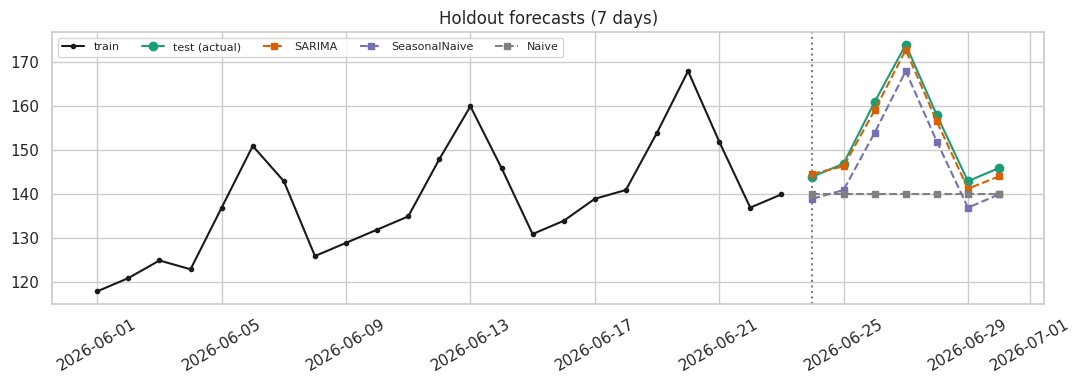

Ljung-Box (lag 7, residuals after differencing burn-in) p = 0.584  → no evidence of residual autocorrelation


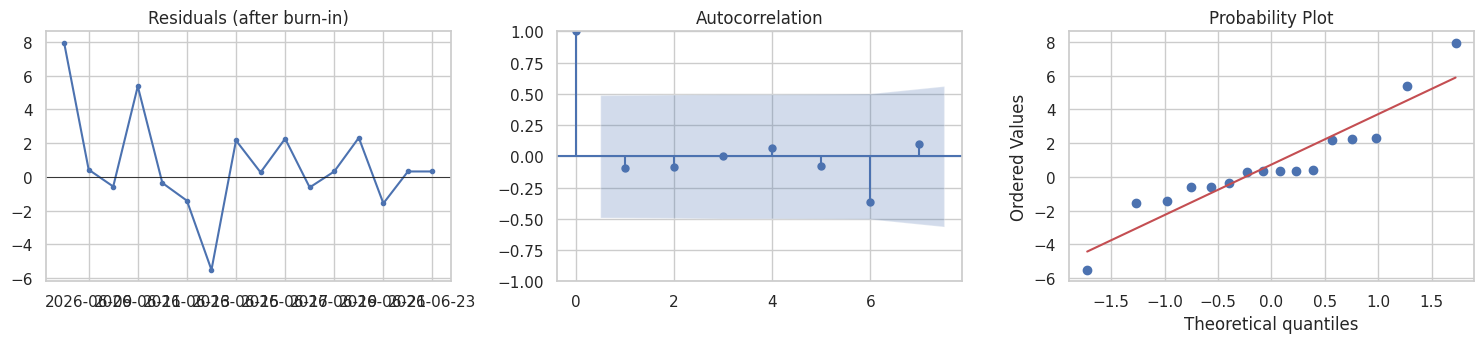

In [5]:
hold, preds, actual, res_tr, lb_p = fc.evaluate_split(y, order, sorder)
display(hold.round(3)); hold.round(4).to_csv(TABLES / "04_holdout_metrics.csv", index=False)
rule = hold.set_index("model").RMSE
print("Preregistered rule: SARIMA recommended only if its RMSE < seasonal-naive RMSE →", rule["SARIMA"] < rule["SeasonalNaive"], f"({rule['SARIMA']:.2f} vs {rule['SeasonalNaive']:.2f})")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index, train, "k-o", ms=3, label="train"); ax.plot(test.index, test, "-o", color="#1b9e77", label="test (actual)")
for k, c in [("SARIMA", "#d95f02"), ("SeasonalNaive", "#7570b3"), ("Naive", "grey")]: ax.plot(test.index, preds[k], "--s", color=c, ms=4, label=f"{k}")
ax.axvline(test.index[0], color="grey", ls=":"); ax.set_title("Holdout forecasts (7 days)"); ax.legend(ncol=5, fontsize=8); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIGS / "04_holdout.png", dpi=150); plt.show()
print(f"Ljung-Box (lag 7, residuals after differencing burn-in) p = {lb_p:.3f}  → {'no evidence of residual autocorrelation' if lb_p >= .05 else 'residual autocorrelation present'}")
burn = order[1] + sorder[3] * sorder[1]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6)); r = res_tr.resid.iloc[max(burn, 1):]
ax[0].plot(r, "o-", ms=3); ax[0].axhline(0, color="k", lw=.6); ax[0].set_title("Residuals (after burn-in)"); plot_acf(r, lags=7, ax=ax[1]); stats.probplot(r, plot=ax[2])
plt.tight_layout(); plt.savefig(FIGS / "04_residuals.png", dpi=150); plt.show()

## 5. Final model refit on all 30 days → 30-day forecast (2026-07-01 … 2026-07-30)

,forecast,lo80,hi80,lo95,hi95
date,,,,,
2026-07-01,149.8,147.2,152.3,145.9,153.6
2026-07-02,152.5,149.0,156.0,147.1,157.9
2026-07-03,166.3,162.1,170.5,159.8,172.8
2026-07-04,179.1,174.3,183.9,171.8,186.4
2026-07-05,162.9,157.6,168.1,154.9,170.9
2026-07-06,147.7,142.1,153.3,139.1,156.3
2026-07-07,150.5,144.5,156.5,141.4,159.6
2026-07-08,154.1,146.6,161.5,142.7,165.5
2026-07-09,156.7,148.1,165.2,143.6,169.8


…


,forecast,lo80,hi80,lo95,hi95
date,,,,,
2026-07-28,158.3,133.8,182.8,120.8,195.8
2026-07-29,161.6,135.8,187.3,122.2,200.9
2026-07-30,163.8,137.1,190.6,122.9,204.8


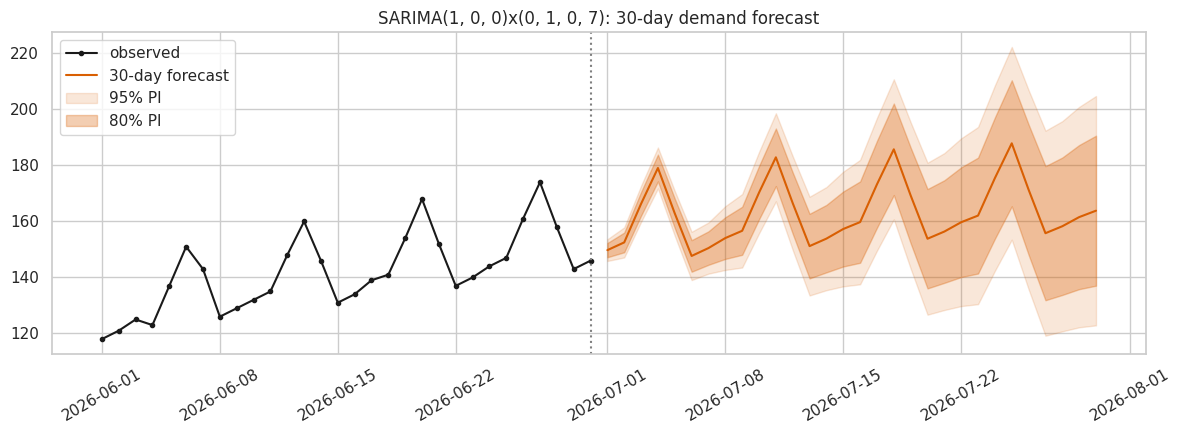

In [6]:
fcst, res_all = fc.forecast_future(y, order, sorder, HORIZON)
fcst.round(2).to_csv(TABLES / "04_forecast_30d.csv"); display(fcst.round(1).head(10)); print("…"); display(fcst.round(1).tail(3))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y.index, y, "k-o", ms=3, label="observed"); ax.plot(fcst.index, fcst.forecast, "-", color="#d95f02", label="30-day forecast")
ax.fill_between(fcst.index, fcst.lo95, fcst.hi95, color="#d95f02", alpha=.15, label="95% PI"); ax.fill_between(fcst.index, fcst.lo80, fcst.hi80, color="#d95f02", alpha=.3, label="80% PI")
ax.axvline(y.index[-1], color="grey", ls=":"); ax.set_title(f"SARIMA{order}x{sorder}: 30-day demand forecast"); ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIGS / "04_forecast_30d.png", dpi=150); plt.show()

In [7]:
wk = fcst.forecast.groupby(fcst.index.to_period("W")).mean().round(1)
wk_txt = "; ".join(f"week of {p.start_time:%b %d}: {v}" for p, v in wk.items()) + " (last week is partial, 4 days)"
display(Markdown(f"""## Findings

* **Decomposition.** A strong weekly cycle (peak Saturday, trough Monday) on top of a clear upward trend through June (weekly means rise from ≈131 to ≈152 over weeks 1–4).
* **Stationarity.** ADF on the level gives p = {adf.p_value.iloc[0]:.3f} (lag {int(adf.used_lag.iloc[0])}), so the preregistered rule sets **d = {d_rule}** (no non-seasonal differencing). Seasonal differencing (D) was left to AICc and was selected (D = {sorder[1]}). ADF has low power at n = 30, so this is a modest result.
* **Model.** Selected on the training window: SARIMA{order}x{sorder} (AICc = {best.aicc:.1f}). The AICc comparison across D = 0 and D = 1 is approximate (see preregistration).
* **Accuracy (7-day holdout).** SARIMA MAPE = {hold.set_index('model').loc['SARIMA','MAPE']:.2f}%, RMSE = {rule['SARIMA']:.2f}; seasonal-naive MAPE = {hold.set_index('model').loc['SeasonalNaive','MAPE']:.2f}%, RMSE = {rule['SeasonalNaive']:.2f}; naive RMSE = {rule['Naive']:.2f}. The preregistered rule is met, so SARIMA is recommended. Seasonal-naive loses mainly because it ignores the weekly upward drift.
* **Diagnostics.** Ljung-Box p = {lb_p:.2f}: no evidence of residual autocorrelation.
* **Forecast.** 30-day mean forecast by week: {wk_txt}. The 95% interval widens from ±{(fcst.hi95.iloc[0]-fcst.lo95.iloc[0])/2:.1f} on day 1 to ±{(fcst.hi95.iloc[-1]-fcst.lo95.iloc[-1])/2:.1f} on day 30.
* **Caveats.** Only 4 weekly cycles and a 7-point test set: the accuracy estimate is itself very uncertain, and the extremely low error suggests a highly regular series. The forecast assumes the June weekly pattern and the recent upward drift persist; it cannot anticipate regime changes (e.g. calendar events outside June).
"""))

## Findings

* **Decomposition.** A strong weekly cycle (peak Saturday, trough Monday) on top of a clear upward trend through June (weekly means rise from ≈131 to ≈152 over weeks 1–4).
* **Stationarity.** ADF on the level gives p = 0.015 (lag 3), so the preregistered rule sets **d = 0** (no non-seasonal differencing). Seasonal differencing (D) was left to AICc and was selected (D = 1). ADF has low power at n = 30, so this is a modest result.
* **Model.** Selected on the training window: SARIMA(1, 0, 0)x(0, 1, 0, 7) (AICc = 79.7). The AICc comparison across D = 0 and D = 1 is approximate (see preregistration).
* **Accuracy (7-day holdout).** SARIMA MAPE = 0.88%, RMSE = 1.44; seasonal-naive MAPE = 3.92%, RMSE = 6.02; naive RMSE = 17.03. The preregistered rule is met, so SARIMA is recommended. Seasonal-naive loses mainly because it ignores the weekly upward drift.
* **Diagnostics.** Ljung-Box p = 0.58: no evidence of residual autocorrelation.
* **Forecast.** 30-day mean forecast by week: week of Jun 29: 162.1; week of Jul 06: 161.2; week of Jul 13: 164.4; week of Jul 20: 166.7; week of Jul 27: 159.9 (last week is partial, 4 days). The 95% interval widens from ±3.9 on day 1 to ±41.0 on day 30.
* **Caveats.** Only 4 weekly cycles and a 7-point test set: the accuracy estimate is itself very uncertain, and the extremely low error suggests a highly regular series. The forecast assumes the June weekly pattern and the recent upward drift persist; it cannot anticipate regime changes (e.g. calendar events outside June).
